---
title: "ERCOT Ancillary Analysis"
format:
  html:
    echo: false
---

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [6]:

ercot_mcpc = pd.read_csv("../data/ercot_mcpc_comparison.csv")
ercot_mcpc["interval_start_local"] = pd.to_datetime(ercot_mcpc["interval_start_local"])

Ancillary services are services that support the reliable operation of the electricity grid by maintaining the balance between supply and demand, for example by providing reserve energy during outages or congestion. MCPC is the Market Clearing Price for Capacity, the price paid for each ancillary service in a given interval.

In this analysis of ERCOT’s ancillary services, we found a large initial spike in the daily median price after the launch of RTC+B, which then settled to a level slightly above the pre-RTC+B baseline for the same time of year in 2024.

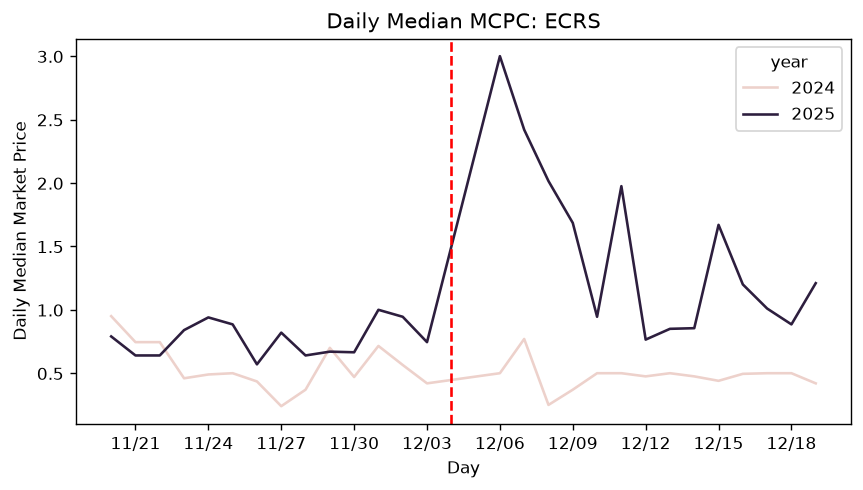

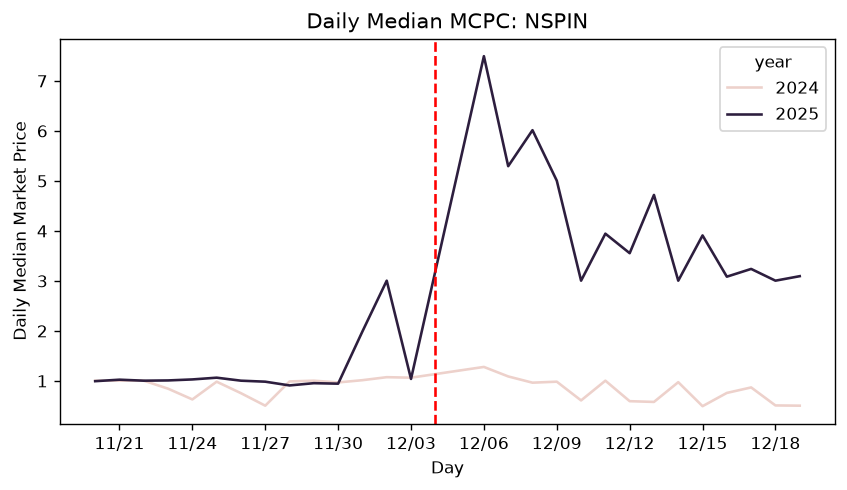

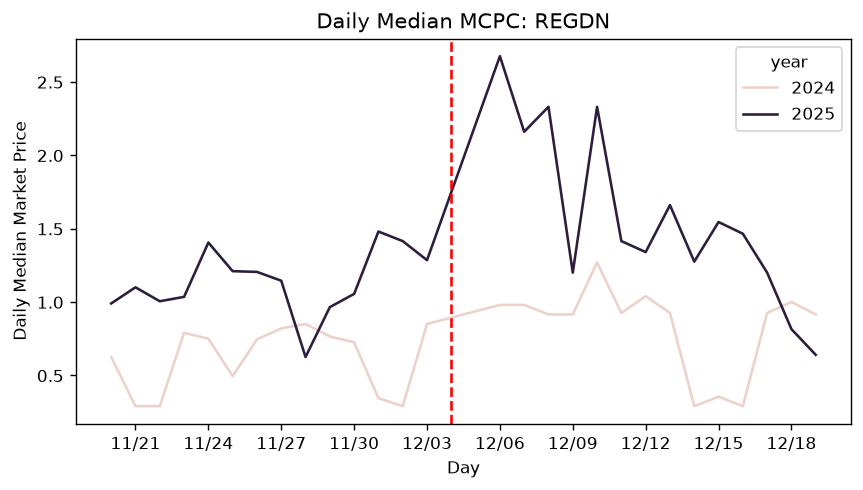

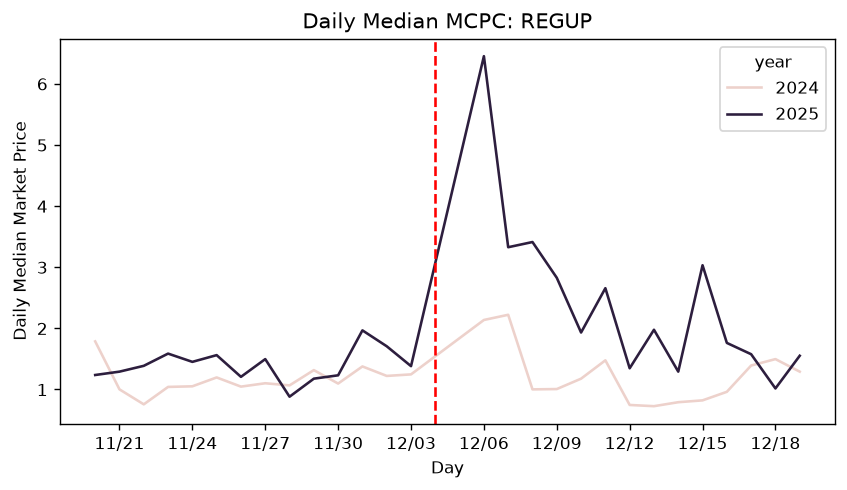

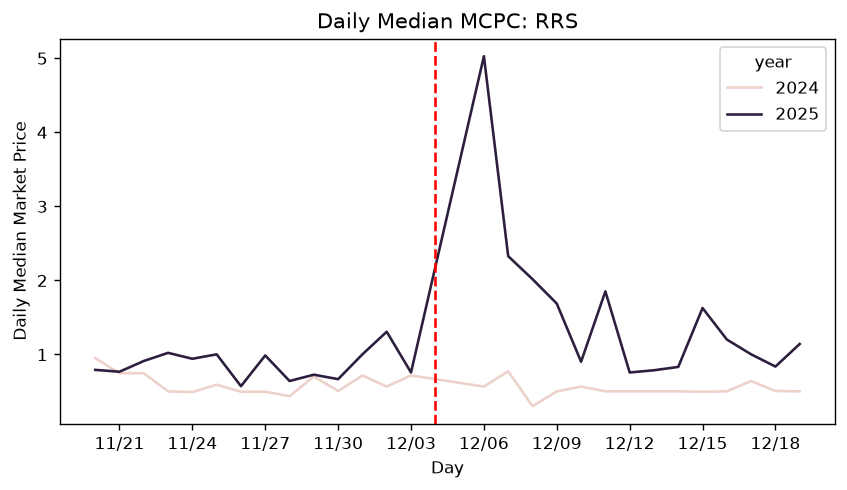

In [8]:
as_types = ercot_mcpc["as_type"].unique()

for as_type in as_types:
    plot_df = (
        ercot_mcpc.query("as_type == @as_type")
        .assign(date=lambda x: x["interval_start_local"].dt.strftime('%m/%d'))
        .groupby(["date", "year"], as_index=False)
        .agg(median_daily=("mcpc", "median"))
    )
   
    plot_df["date"] = pd.to_datetime(plot_df["date"], format="%m/%d")

    fig, ax = plt.subplots(figsize=(8, 4))
    sns.lineplot(data=plot_df, x="date",
     y="median_daily",
      hue="year",
       ax=ax)

    ax.axvline(x=pd.to_datetime("12/04",
     format="%m/%d"),
      color="red",
       linestyle="--")
    ax.set_title(f"Daily Median MCPC: {as_type}")
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
    ax.set_ylabel("Daily Median Market Price")
    ax.set_xlabel("Day")
    

    plt.show()
     
